# Phase 2: resource limits and shrimp mortality

This notebook extends the base shrimp?algae?bird model with logistic algae growth and natural shrimp mortality. It is a separate experiment; the phase 1 files are preserved.

**Question:** Can the revised model sustain stable coexistence across a range of bird mortality rates?

Run the cells in order. Edit the parameter cell to explore alternatives. Values are illustrative, not calibrated to Great Salt Lake observations. Time and population scales are unspecified model units.

## Equations

The state order throughout the code is **shrimp, algae, birds**: $(S,A,B)$.

$$
\frac{dS}{dt} = \gamma_S C_A S A - C_S S B - \delta_S S
$$

$$
\frac{dA}{dt} = \beta_A A(1-A/K) - C_A S A
$$

$$
\frac{dB}{dt} = -\delta_B B + \gamma_B C_S S B
$$

$K>0$ is the algae carrying capacity in the absence of grazing. $\delta_S>0$ is the shrimp natural mortality rate. Feeding and conversion terms retain their phase 1 meanings. These changes do not yet include salinity, lake volume, seasonal forcing, or harvesting.

In [1]:
from dataclasses import dataclass, replace
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

@dataclass(frozen=True)
class Parameters:
    beta_A: float = 1.0
    C_A: float = 0.5
    C_S: float = 0.4
    gamma_S: float = 0.2  # Illustrative conversion efficiency
    gamma_B: float = 0.3
    delta_B: float = 0.12
    K: float = 10.0       # New: illustrative algae carrying capacity
    delta_S: float = 0.1  # New: illustrative shrimp mortality

p = Parameters()
y0 = np.array([1.0, 6.0, 0.5])  # S, A, B
T = 400.0
print(p)

Parameters(beta_A=1.0, C_A=0.5, C_S=0.4, gamma_S=0.2, gamma_B=0.3, delta_B=0.12, K=10.0, delta_S=0.1)


In [2]:
def rhs(t, state, p):
    S, A, B = state
    return np.array([
        p.gamma_S*p.C_A*S*A - p.C_S*S*B - p.delta_S*S,
        p.beta_A*A*(1 - A/p.K) - p.C_A*S*A,
        -p.delta_B*B + p.gamma_B*p.C_S*S*B,
    ])

def simulate(p, initial=y0, duration=T):
    if any(v <= 0 for v in vars(p).values()):
        raise ValueError('All parameters must be positive.')
    initial = np.asarray(initial, dtype=float)
    if initial.shape != (3,) or np.any(initial < 0):
        raise ValueError('Initial state must contain three nonnegative populations.')
    sol = solve_ivp(lambda t, y: rhs(t, y, p), (0, duration), initial,
                    t_eval=np.linspace(0, duration, 2401), rtol=1e-8, atol=1e-10)
    if not sol.success:
        raise RuntimeError(sol.message)
    if np.min(sol.y) < -1e-7:
        raise RuntimeError('Negative numerical populations: inspect solver settings.')
    return sol

sol = simulate(p)

## Coexistence equilibrium

For all three populations to be positive, dividing the equilibrium equations by their respective populations gives:

$$
S^* = \frac{\delta_B}{\gamma_B C_S}
$$

$$
A^* = K\left(1-\frac{C_A S^*}{\beta_A}\right)
$$

$$
B^* = \frac{\gamma_S C_A A^* - \delta_S}{C_S}
$$

Thus positive coexistence requires

$$
\gamma_S C_A K > \delta_S
$$

and

$$
0 < \delta_B < \frac{\gamma_B C_S \beta_A}{C_A}
\left(1-\frac{\delta_S}{\gamma_S C_A K}\right).
$$

This replaces the phase 1 equality condition with an interval. At any strictly positive coexistence equilibrium, the Jacobian characteristic polynomial has the form $\lambda^3+x\lambda^2+(uw+vy)\lambda+xvy$, with $x=\beta_A A^*/K$, $u=\gamma_S C_A S^*$, $v=C_S S^*$, $w=C_A A^*$, and $y=\gamma_B C_S B^*$. All are positive and $x(uw+vy)>xvy$, so the Routh?Hurwitz criterion gives **local asymptotic stability**. This is a local result; trajectories below provide numerical examples, not a proof of global convergence.

In [3]:
def coexistence(p):
    S = p.delta_B/(p.gamma_B*p.C_S)
    A = p.K*(1 - p.C_A*S/p.beta_A)
    B = (p.gamma_S*p.C_A*A - p.delta_S)/p.C_S
    return np.array([S, A, B])

def jacobian(state, p):
    S, A, B = state
    return np.array([
        [p.gamma_S*p.C_A*A-p.C_S*B-p.delta_S, p.gamma_S*p.C_A*S, -p.C_S*S],
        [-p.C_A*A, p.beta_A*(1-2*A/p.K)-p.C_A*S, 0],
        [p.gamma_B*p.C_S*B, 0, -p.delta_B+p.gamma_B*p.C_S*S],
    ])

eq = coexistence(p)
threshold = p.gamma_B*p.C_S*p.beta_A/p.C_A*(1-p.delta_S/(p.gamma_S*p.C_A*p.K))
print('Coexistence candidate [S, A, B]:', eq)
print('Upper bird mortality bound:', threshold)
if np.all(eq > 0):
    assert np.allclose(rhs(0, eq, p), 0, atol=1e-10)
    eigenvalues = np.linalg.eigvals(jacobian(eq, p))
    print('Jacobian eigenvalues:', eigenvalues)
    print('Locally stable:', np.all(eigenvalues.real < 0))
else:
    print('The coexistence candidate is not strictly positive for these parameters.')

Coexistence candidate [S, A, B]: [1. 5. 1.]
Upper bird mortality bound: 0.216
Jacobian eigenvalues: [-0.20391936+0.46779264j -0.20391936-0.46779264j -0.09216128+0.j        ]
Locally stable: True


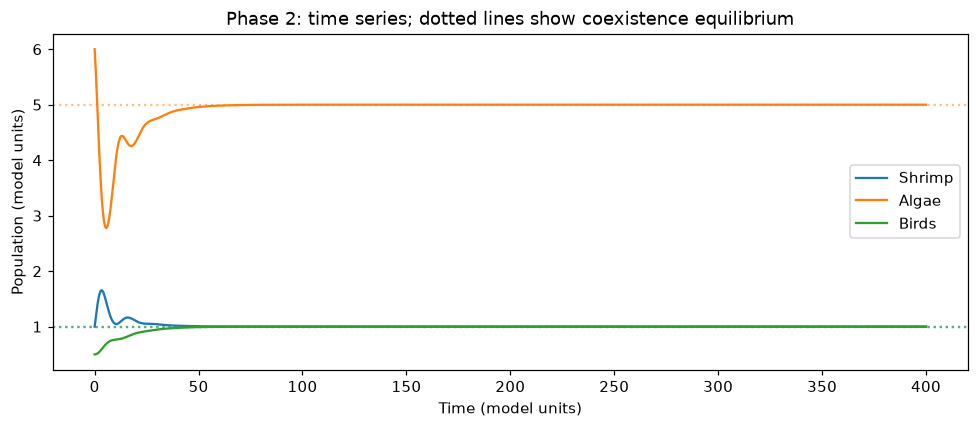

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
for i, label in enumerate(['Shrimp', 'Algae', 'Birds']):
    line, = ax.plot(sol.t, sol.y[i], label=label)
    if np.all(eq > 0):
        ax.axhline(eq[i], color=line.get_color(), linestyle=':', alpha=0.5)
ax.set(xlabel='Time (model units)', ylabel='Population (model units)',
       title='Phase 2: time series; dotted lines show coexistence equilibrium')
ax.legend()
fig.tight_layout()
plt.show()

## Shrimp?algae phase portrait without birds

Setting $B=0$ gives an invariant two-dimensional subsystem. Its nonzero nullclines are $A=\delta_S/(\gamma_S C_A)$ and $S=(\beta_A/C_A)(1-A/K)$. A positive shrimp?algae equilibrium exists when $\gamma_S C_A K>\delta_S$. This plot concerns the bird-free subsystem; it is not a slice through the full three-species dynamics.

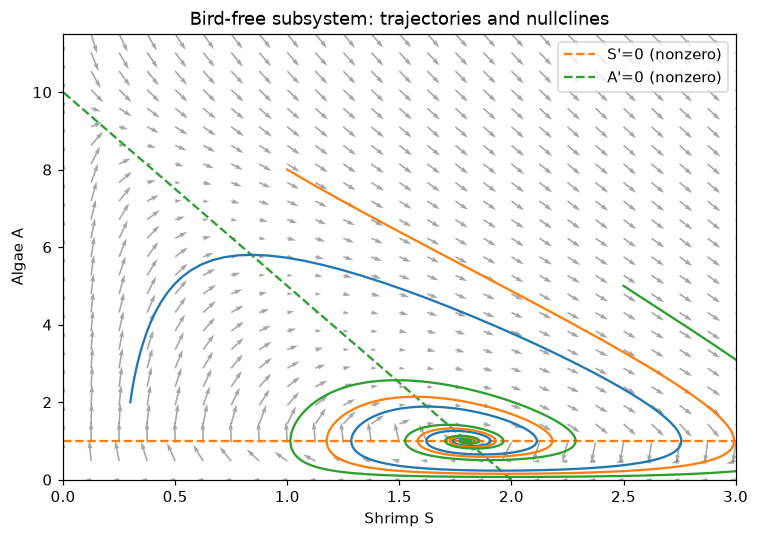

In [5]:
Smax = 1.5*p.beta_A/p.C_A
Amax = 1.15*p.K
sg = np.linspace(0, Smax, 25)
ag = np.linspace(0, Amax, 25)
SS, AA = np.meshgrid(sg, ag)
dS = SS*(p.gamma_S*p.C_A*AA-p.delta_S)
dA = AA*(p.beta_A*(1-AA/p.K)-p.C_A*SS)
# Normalize by each axis range to keep direction arrows readable.
speed = np.hypot(dS/Smax, dA/Amax)
scale = np.maximum(speed, 1e-12)
fig, ax = plt.subplots(figsize=(7, 5))
ax.quiver(SS, AA, dS/scale, dA/scale, alpha=0.35, angles='xy')
ax.axhline(p.delta_S/(p.gamma_S*p.C_A), color='tab:orange', linestyle='--', label="S'=0 (nonzero)")
a_line = np.linspace(0, p.K, 200)
ax.plot(p.beta_A/p.C_A*(1-a_line/p.K), a_line, '--', color='tab:green', label="A'=0 (nonzero)")
for initial in ([0.3, 2, 0], [1.0, 8, 0], [2.5, 5, 0]):
    trajectory = simulate(p, initial)
    ax.plot(trajectory.y[0], trajectory.y[1], linewidth=1.5)
ax.set(xlim=(0, Smax), ylim=(0, Amax), xlabel='Shrimp S', ylabel='Algae A',
       title='Bird-free subsystem: trajectories and nullclines')
ax.legend()
fig.tight_layout()
plt.show()

## Change bird mortality

Compare mortality rates below and above the positive coexistence threshold. The simulations use the same initial populations. Finite-time small populations should not be interpreted as an exact extinction event.

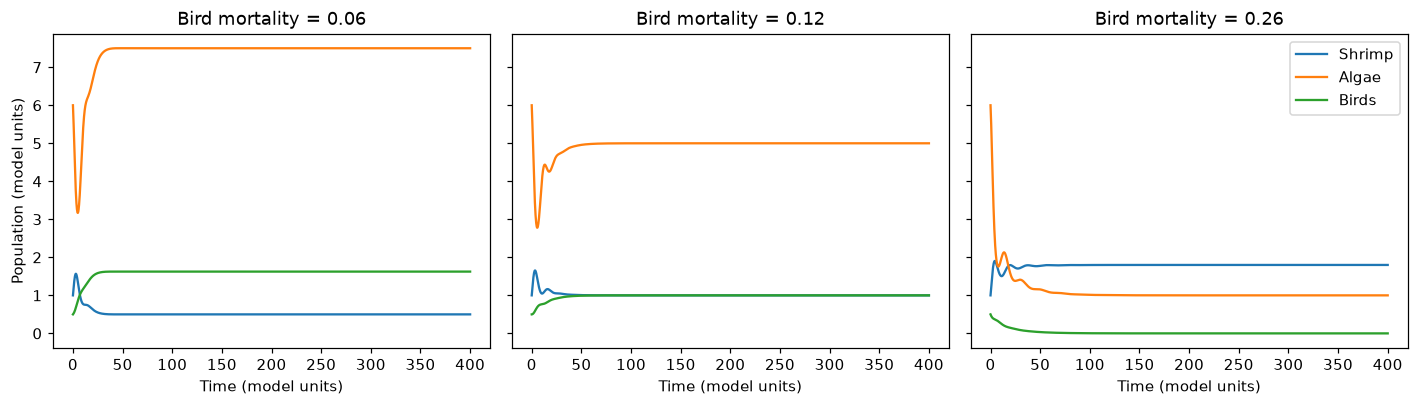

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharex=True, sharey=True)
for ax, mortality in zip(axes, [0.06, 0.12, 0.26]):
    trial = replace(p, delta_B=mortality)
    result = simulate(trial)
    for i, label in enumerate(['Shrimp', 'Algae', 'Birds']):
        ax.plot(result.t, result.y[i], label=label)
    ax.set(title=f'Bird mortality = {mortality}', xlabel='Time (model units)')
axes[0].set_ylabel('Population (model units)')
axes[-1].legend()
fig.tight_layout()
plt.show()

## Next experiments

- Change `K` and `delta_S` in the parameter cell, then rerun all cells.
- Compare several positive initial conditions at fixed parameters.
- Investigate the boundary equilibria when positive coexistence fails.
- Choose population and time units, then estimate parameters from observations before making ecological predictions.

Plots are embedded in the notebook; this notebook does not overwrite or export project images.